In [1]:
import numpy as np
import random
import scipy.special
import matplotlib.pyplot as plt

Clearly when we are dealing with stochastic processes the binomial theorem will come into play. Our Ehrenfest model is a 2-state system ($2^N$ number of microstates). We use the binomial theorem to calculate the probability of our system being in a macrostate (where X = N + 1). \
\
Say my box has N = 100 particles, therefore X $\in$ {0, 1, 2 ... 100}. What is the probability it is in macrostate X = 50? \
\
$$ \mathbb P\{X = k\} = \frac{1}{2^N} \binom{N}{k} = \frac{1}{2^N} \frac{N!}{k! (N-k)!}$$

In [29]:
N = 100
binom = scipy.special.binom(N, 50)
print(binom)
norm = 1 / 2**N
print(norm * binom)

1.0089134454556415e+29
0.07958923738717873


Consider a Galton board with 10 levels. At each level, when a ball hits an obstacle, it has 0.5 chance of going either left or right. What does the distribution look like?

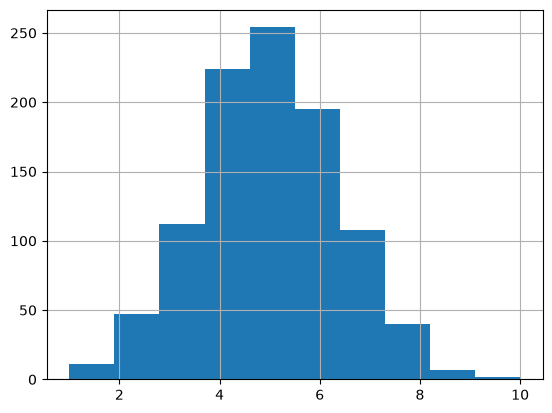

In [15]:
x = np.random.binomial(10, 0.5, 1000)               # Third parameter is the number of trials
plt.hist(x)
plt.grid(True)

# The law of large numbers:

For any $\delta$ > 0, the probability that $\frac{X}{N} \in [\frac{1}{2} - \delta, \frac{1}{2} + \delta]$ goes to 1 and N $\to \infty$.

(0.0, 1000.0)

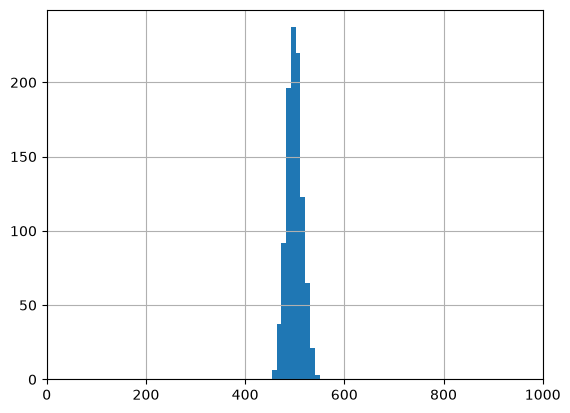

In [20]:
x = np.random.binomial(1000, 0.5, 1000)               # Third parameter is the number of trials
plt.hist(x)
plt.grid(True)
plt.xlim(0, 1000)

# The Central Limit Theorem:

As N $\to \infty$:
$$\hat X = \frac{X - \frac{N}{2}}{\sqrt \frac{N}{4}}$$
approaches a normal distribution with density:
$$\frac{1}{\sqrt{2 \pi}} e^{\frac{-x^2}{2}}$$
The consequence of this is that:
$$ \frac{X}{N} \simeq \frac{1}{2} + \frac{1}{\sqrt{4N}} \mathcal N$$
with $\mathcal N$ standard normal random variable.

# Entropy:

Boltzmann entropy: log of number of microstates per macrostate

$$ log \, \mathbb P\{X = k\} = log\left(\frac{1}{2^N}\binom{N}{k}\right) = -N log 2 + log (N!) - log (k!) - log ( (N - k)! )$$

## Stirling's Formula:

For large N, $log(N!) \simeq Nlog(N)$

# Large Deviations:
Set $ k = Nx $, then:
$$
\begin{aligned}
log \, \mathbb P\{\frac{X}{N} = x\} &= -N \, log 2 + N \, log (N) - Nx \, log (Nx) - N(1-x) \, log (N(1-x)) \\
&= -N \, log 2 - Nx \, log (x) - N(1-x) \, log (1-x) \\
\end{aligned}$$

## Entropy density:
$s(x)$ such that $\mathbb P\{\frac{X}{N} = x\} \simeq e^{Ns(x)}$ for $N >> 1$

$$ s(x) = \lim_{N \to \infty} \frac{1}{N} \mathbb P\{\frac{X}{N} = x\} = -log 2 - x \, log (x) - (1-x) \, log (1-x) $$ 

C:\Users\Fosco\AppData\Local\Temp\ipykernel_2964\1238647867.py:6: RuntimeWarning: divide by zero encountered in log
  s = -np.log(2) - x*np.log(x) - (1-x)*np.log(1-x)
C:\Users\Fosco\AppData\Local\Temp\ipykernel_2964\1238647867.py:6: RuntimeWarning: invalid value encountered in multiply
  s = -np.log(2) - x*np.log(x) - (1-x)*np.log(1-x)


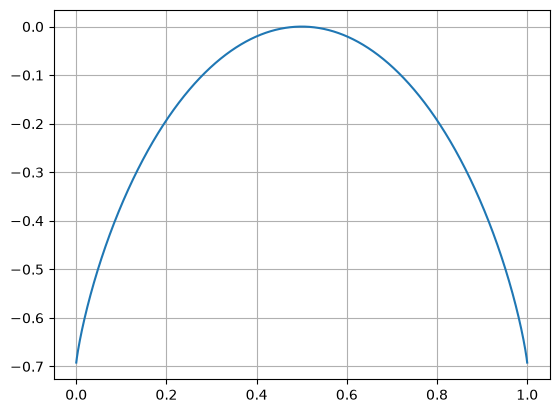

In [26]:
# This will show that max entropy will happen at 0.5
N = 10000
X = np.arange(1, N+1, 1)
x = X / N

s = -np.log(2) - x*np.log(x) - (1-x)*np.log(1-x)
plt.plot(x, s)
plt.grid(True)

According to Nils Berglund, this is as far as we get without dynamics.\
\
He explains that the above explains why we saw an approximately 50/50 distribution of atoms in the box with partition model. \
\
Cool stuff:\
\
Avogadro's number: $ 6.022 \times 10^{23}$
\
Say you have $N_A$ cubes of sidelength of 1 cm, if you stack of all them inside a large cube, the side length of the cube would have 800 km. \
\
If we put each cube next to each other and stack them when it fills the radius of the Earth, it would cover the Earth with a layer of 1000 m. \
\
If you chain them side by side, all the cubes would add up to approximately 600,000 light years!!! \
\
https://www.youtube.com/watch?v=zLJhUrNC_hI&t=1s \
\
Why does this matter? Because the CLT says that the average proportion of atoms in each container (X / N) will equal $ \frac{1}{2} \pm \frac{1}{\sqrt{4N}} $. \
\
$\frac{1}{\sqrt{4N_A}} \simeq 10^{-13}$ - this crazy amount of fluctuation ensures that it will not be seen.